# Листок 3 Прикладные дифференциальные уравнения

Полные решения задач **3.1–3.5** по листку П. Е. Рябова. Для каждой задачи приведены
постановка, аналитический вывод, проверка формул, статический рисунок и анимация.
В исходном листке нет отдельных вариантов: выполнены все пять задач.

Параметры задаются в ячейках; единицы СИ. Сопротивлением воздуха и трением пренебрегаем.
Результаты вычислений сохранены. HTML-анимации с кнопками воспроизведения,
паузы и ползунком находятся в ноутбуке и в каталоге `animations`.
GitHub может скрывать интерактивный HTML: для управления анимацией откройте
скачанный HTML в браузере или ноутбук в доверенном Jupyter.

In [1]:
from pathlib import Path
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import display, HTML, IFrame
from scipy.integrate import solve_ivp, quad
from scipy.special import ellipk, ellipj

plt.rcParams.update({'figure.dpi': 100, 'font.size': 10,
                     'axes.grid': True, 'grid.alpha': .25})
plt.rcParams['animation.embed_limit'] = 80
figures = Path('figures'); figures.mkdir(exist_ok=True)
animations = Path('animations'); animations.mkdir(exist_ok=True)
g = 9.81

def save_plot(fig, name):
    fig.tight_layout()
    fig.savefig(figures / (name + '.png'), dpi=160, bbox_inches='tight')
    plt.show()

def show_animation(fig, update, name, frames=80, interval=65):
    animation = FuncAnimation(fig, update, frames=frames, interval=interval,
                              blit=False, repeat=True)
    html = animation.to_jshtml(fps=1000/interval, default_mode='once')
    (animations / (name + '.html')).write_text(
        '<!doctype html><html lang="ru"><meta charset="utf-8">'
        '<title>' + name + '</title>' + html + '</html>', encoding='utf-8')
    plt.close(fig)
    display(HTML('<p><a href="animations/' + name + '.html" target="_blank">Открыть анимацию отдельно</a></p>'))
    display(IFrame(src='animations/' + name + '.html', width=850, height=550))
    return animation

## 3.1 Задача о равномерном спуске

**Требование:** постоянна именно вертикальная составляющая скорости,
$\dot y=-c$, $c>0$. Полная скорость постоянной не является. Ось $y$ направлена вверх.
Берём $x(0)=x_0$, $y(0)=y_0$, $\dot x(0)=u_0>0$ и гладкую неподвижную направляющую.

Сила реакции $\mathbf N$ перпендикулярна скорости. Скалярно умножим
$m\ddot{\mathbf r}=(0,-mg)+\mathbf N$ на $\dot{\mathbf r}$:
$$m(\dot x\ddot x+\dot y\ddot y)=-mg\dot y.$$
Поскольку $\ddot y=0$, реакция исключается и получается
$$\dot x\ddot x=gc,\qquad \frac{d}{dt}(\dot x^2)=2gc.$$
Интегрирование с начальными условиями даёт
$$\dot x=\sqrt{u_0^2+2gct},\quad y=y_0-ct,$$
$$x=x_0+\frac{(u_0^2+2gct)^{3/2}-u_0^3}{3gc}.$$
Исключаем время:
$$\boxed{y(x)=y_0-\frac{[u_0^3+3gc(x-x_0)]^{2/3}-u_0^2}{2g}},\quad x\ge x_0.$$
В координатах $X=x-x_0+u_0^3/(3gc)$, $Y=y_0+u_0^2/(2g)-y$
имеем $X^2=8gY^3/(9c^2)$: это ветвь полукубической параболы.

**ДУ непосредственно для кривой.** Из $y'=-c/\dot x$ следует
$y''=c\ddot x/\dot x^3=(g/c^2)(y')^4$.
Начальные условия: $y(x_0)=y_0$, $y'(x_0)=-c/u_0$.
Эквивалентное интегрирование: $d(p^{-3})/dx=-3g/c^2$, где $p=y'<0$.

Реакция $\mathbf N=m(gc/\dot x,g)$ имеет нулевую мощность:
$\mathbf N\cdot\dot{\mathbf r}=0$. Энергия $m(\dot x^2+c^2)/2+mgy$ постоянна.
При $u_0=0$ вершина ветви вырожденная: ускорение по $x$ неограниченно;
для гладкой регулярной направляющей начинаем с $u_0>0$.
Случай движения влево получается отражением относительно вертикали.

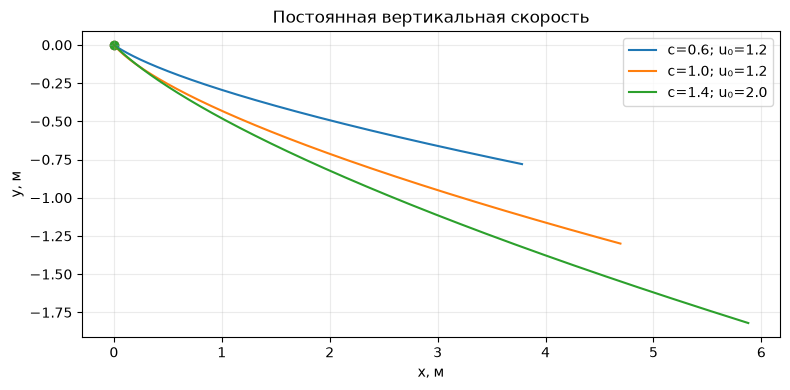

Проверены: vy = −c, ДУ кривой, баланс мощности и сохранение энергии.


In [2]:
tau = np.linspace(0, 1.3, 400)
def uniform_descent(t, c=1., u0=1.2, x0=0., y0=0.):
    t = np.asarray(t)
    return x0 + ((u0*u0+2*g*c*t)**1.5-u0**3)/(3*g*c), y0-c*t

# Независимая символьная проверка скорости, ДУ и закона энергии.
t, c, u0, grav = sp.symbols('t c u0 g', positive=True)
xx = ((u0**2+2*grav*c*t)**sp.Rational(3,2)-u0**3)/(3*grav*c)
yy = -c*t
vx = sp.diff(xx,t)
assert sp.simplify(vx*sp.diff(vx,t)-grav*c)==0
slope = sp.diff(yy,t)/vx
assert sp.simplify(sp.diff(slope,t)/vx-grav/c**2*slope**4)==0
energy = (vx**2+c**2)/2+grav*yy
assert sp.simplify(sp.diff(energy,t))==0

fig, ax = plt.subplots(figsize=(8,4))
for vertical_speed, initial_vx in [(0.6,1.2),(1.,1.2),(1.4,2.)]:
    X,Y=uniform_descent(tau,vertical_speed,initial_vx)
    ax.plot(X,Y,label=f'c={vertical_speed}; u₀={initial_vx}')
    ax.scatter(X[0],Y[0],s=35)
ax.set(xlabel='x, м',ylabel='y, м',title='Постоянная вертикальная скорость')
ax.legend(); save_plot(fig,'3_1_uniform_descent')
print('Проверены: vy = −c, ДУ кривой, баланс мощности и сохранение энергии.')

In [3]:
times=np.linspace(0,1.3,80)
X,Y=uniform_descent(times)
fig,ax=plt.subplots(figsize=(7,3.8),dpi=70)
ax.plot(X,Y,color='.7'); trail,=ax.plot([],[],color='tab:blue')
point,=ax.plot([],[],'o',color='tab:red',ms=8)
label=ax.text(.03,.08,'',transform=ax.transAxes)
ax.set(xlim=(-.1,X.max()+.2),ylim=(Y.min()-.15,.15),xlabel='x, м',ylabel='y, м')
ax.set_title('3.1 Спуск при vy = −1 м/с')
def update_descent(i):
    trail.set_data(X[:i+1],Y[:i+1]);point.set_data([X[i]],[Y[i]])
    label.set_text(f't={times[i]:.2f} с; vy=−1 м/с; vx={np.sqrt(1.2**2+2*g*times[i]):.2f} м/с')
anim31=show_animation(fig,update_descent,'3_1_uniform_descent')

## 3.2 Бильярд в прямоугольнике

Область $0\le x\le a$, $0\le y\le b$. Между ударами
$\ddot x=\ddot y=0$. При отражении от вертикальной стенки
$v_x^+=-v_x^-$, $v_y^+=v_y^-$; от горизонтальной — наоборот.
Скорость и энергия сохраняются. Удары точно в угол исключаем:
у угла нет единственной нормали, поэтому обычный закон отражения там неоднозначен.

**Развёртка.** Вместо отражения скорости отражаем прямоугольник.
В развёрнутой плоскости
$$u=x_0+v_xt,\qquad w=y_0+v_yt.$$
Складывание зеркальных копий задаёт треугольная функция
$$F_L(z)=L-|((z\bmod 2L)-L)|,$$
$$x(t)=F_a(u(t)),\qquad y(t)=F_b(w(t)).$$
После отождествления $u\sim u+2a$, $w\sim w+2b$ получаем прямолинейный
поток на торе $\mathbb R^2/(2a\mathbb Z\times2b\mathbb Z)$.

**Периодичность.** Для возвращения и координат, и скорости нужны
$v_xT=2am$, $v_yT=2bn$ с целыми $m,n$.
Если обе компоненты ненулевые, это эквивалентно
$$\rho=\frac{v_y a}{v_x b}\in\mathbb Q.$$
При $\rho=p/q$ в несократимом виде и $v_x>0$ можно взять
$T=2aq/v_x$. При нулевой компоненте имеем периодическое движение между
двумя противоположными стенками.
Если $\rho$ иррационально, орбита плотна и равномерно распределена на торе.
Линейный поток с этим фиксированным иррациональным направлением эргодичен,
но не смешивает. Полный бильярд на всём энергетическом слое не эргодичен:
величины $|v_x|$, $|v_y|$ сохраняются. Плотность конечного нарисованного
отрезка сама по себе не является доказательством эргодичности.

**Гамильтонова форма.** Между ударами
$$H=(p_x^2+p_y^2)/(2m),\quad \dot x=p_x/m,\ \dot p_x=0,$$
и аналогично для $y$. На стенке меняется знак нормального импульса;
в развёртке импульс постоянен. Для визуального тора используем
$\phi=\pi u/a$, $\psi=\pi w/b$,
$\mathbf r=((R+r\cos\psi)\cos\phi,(R+r\cos\psi)\sin\phi,r\sin\psi)$.

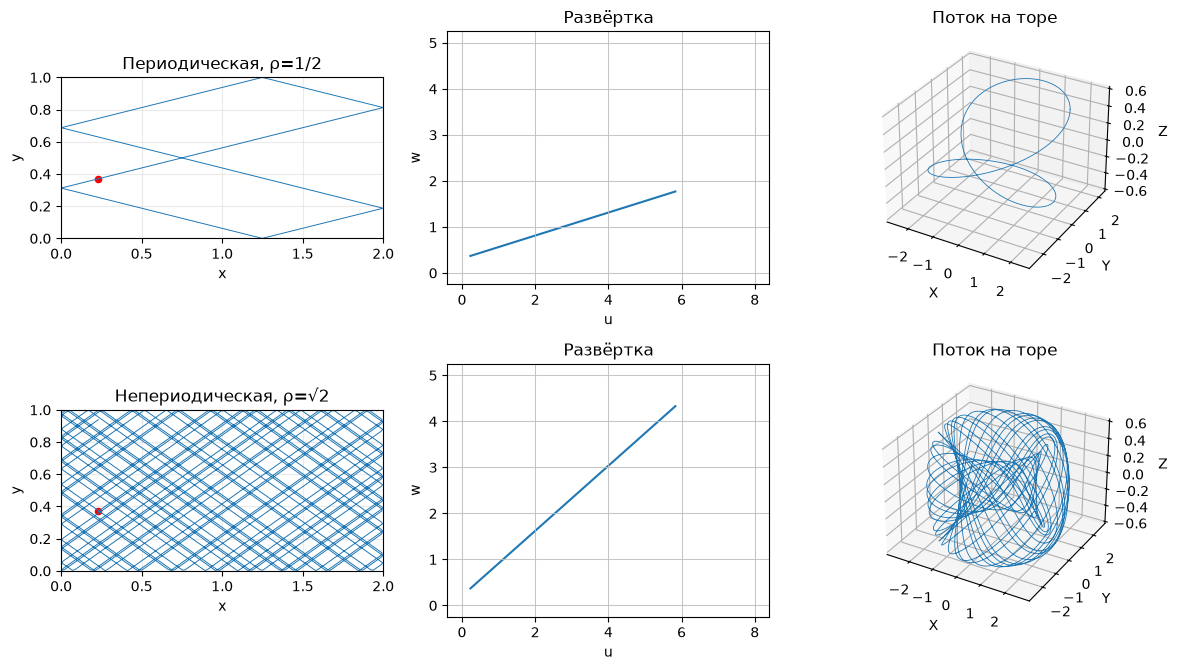

Период рационального примера T=4 с. Возврат состояния проверен.


In [4]:
a,b=2.,1.
initial=np.array([.23,.37])
velocities=[np.array([a,b/2]),np.array([a,np.sqrt(2)*b])]
def fold(z,L): return L-np.abs(np.mod(z,2*L)-L)
def billiard(t,v):
    raw=initial[:,None]+v[:,None]*np.atleast_1d(t)
    return raw,np.vstack([fold(raw[0],a),fold(raw[1],b)])
def torus(raw):
    phi=np.pi*raw[0]/a; psi=np.pi*raw[1]/b
    return np.array([(2+.6*np.cos(psi))*np.cos(phi),
                     (2+.6*np.cos(psi))*np.sin(phi),.6*np.sin(psi)])

raw_periodic,path_periodic=billiard(np.array([0.,4.]),velocities[0])
assert np.allclose(path_periodic[:,0],path_periodic[:,1])
assert np.allclose(np.mod(raw_periodic[:,0],[2*a,2*b]),
                   np.mod(raw_periodic[:,1],[2*a,2*b]))
fig=plt.figure(figsize=(12,6.8))
for row,v in enumerate(velocities):
    sample=np.linspace(0,40 if row else 4,5000)
    raw,path=billiard(sample,v)
    ax=fig.add_subplot(2,3,1+row*3)
    ax.plot(*path,lw=.7);ax.scatter(*initial,color='red',s=20)
    ax.set(xlim=(0,a),ylim=(0,b),xlabel='x',ylabel='y',
           title='Периодическая, ρ=1/2' if row==0 else 'Непериодическая, ρ=√2')
    ax.set_aspect('equal')
    ax=fig.add_subplot(2,3,2+row*3)
    short,_=billiard(np.linspace(0,2.8,300),v)
    ax.plot(*short);ax.set(title='Развёртка',xlabel='u',ylabel='w')
    for k in range(5):ax.axvline(k*a,color='.75',lw=.6)
    for k in range(6):ax.axhline(k*b,color='.75',lw=.6)
    ax=fig.add_subplot(2,3,3+row*3,projection='3d')
    xyz=torus(raw);ax.plot(*xyz,lw=.6)
    ax.set(title='Поток на торе',xlabel='X',ylabel='Y',zlabel='Z')
save_plot(fig,'3_2_billiard')
print('Период рационального примера T=4 с. Возврат состояния проверен.')

In [5]:
times=np.linspace(0,8,80)
fig=plt.figure(figsize=(10,5.5),dpi=65)
items=[]
for row,v in enumerate(velocities):
    raw,path=billiard(times,v);xyz=torus(raw)
    ax=fig.add_subplot(2,3,row*3+1)
    ax.set(xlim=(0,a),ylim=(0,b),xlabel='x',ylabel='y',
           title='ρ=1/2' if row==0 else 'ρ=√2')
    line,=ax.plot([],[],lw=1);dot,=ax.plot([],[],'ro',ms=5)
    un=fig.add_subplot(2,3,row*3+2)
    un.set(xlim=(0,raw[0,-1]+.2),ylim=(0,raw[1,-1]+.2),title='Развёртка',xlabel='u',ylabel='w')
    for k in np.arange(0,raw[0,-1]+a,a):un.axvline(k,color='.8',lw=.5)
    for k in np.arange(0,raw[1,-1]+b,b):un.axhline(k,color='.8',lw=.5)
    uline,=un.plot([],[]);udot,=un.plot([],[],'ro',ms=5)
    tor=fig.add_subplot(2,3,row*3+3,projection='3d')
    tor.set(xlim=(-2.8,2.8),ylim=(-2.8,2.8),zlim=(-.8,.8),title='Тор')
    tl,=tor.plot([],[],[],lw=1);td,=tor.plot([],[],[],'ro',ms=5)
    items.append((path,raw,xyz,line,dot,uline,udot,tl,td))
fig.tight_layout(rect=(0,0,1,.92)); clock=fig.suptitle('',y=.985,fontsize=10)
def update_billiard(i):
    for path,raw,xyz,line,dot,ul,ud,tl,td in items:
        # Плотный след сохраняет вершины отражений между редкими кадрами.
        row=0 if line is items[0][3] else 1
        _,dense=billiard(np.linspace(0,times[i],max(2,20*i+1)),velocities[row])
        line.set_data(*dense);dot.set_data([path[0,i]],[path[1,i]])
        ul.set_data(raw[0,:i+1],raw[1,:i+1]);ud.set_data([raw[0,i]],[raw[1,i]])
        tl.set_data_3d(*xyz[:,:i+1]);td.set_data_3d(*xyz[:,i:i+1])
    clock.set_text(f'3.2 Бильярд и развёртка; t={times[i]:.2f} с; |v| сохраняется')
anim32=show_animation(fig,update_billiard,'3_2_billiard')

## 3.3 Цепная линия

Цепь гибкая, однородная и нерастяжимая, вес единицы **длины цепи** $w=\mu g$.
В нижней точке $x=x_c$ касательная горизонтальна. Горизонтальная составляющая
натяжения $H>0$ постоянна. Для участка от нижней точки до $x$ вертикальная
составляющая натяжения равна $V=ws$, где $s$ — ориентированная длина дуги.
Так как натяжение направлено по касательной,
$$y'=\frac{V}{H}=\frac{s}{a},\qquad a=\frac{H}{w}.$$
Используем $ds/dx=\sqrt{1+(y')^2}$:
$$y''=\frac1a\sqrt{1+(y')^2}.$$
Положим $p=y'$ и разделим переменные:
$$\frac{dp}{\sqrt{1+p^2}}=\frac{dx}{a},\quad
\operatorname{arsinh}p=\frac{x-x_c}{a},\quad
p=\sinh\frac{x-x_c}{a}.$$
Повторное интегрирование даёт
$$\boxed{y=a\cosh\frac{x-x_c}{a}+C}.$$
Если вершину не сдвигать, $C=0$ и $y=a\,\operatorname{ch}(x/a)$.
Для равновысоких опор $x=\pm L$, $y=0$:
$$y=a[\cosh(x/a)-\cosh(L/a)],\quad
\ell=2a\sinh(L/a),\quad d=a[\cosh(L/a)-1].$$
Здесь $\ell$ — длина цепи, $d$ — провисание. При заданных $L$ и $\ell>2L$
параметр $a$ определяется уравнением длины. Натяжение
$T(x)=H\cosh((x-x_c)/a)$ минимально в нижней точке.
При $|x|\ll a$ цепная линия приближённо параболическая, но в общем случае не парабола.

Анимация ниже — **семейство равновесий**, а не динамическое падение одной
нерастяжимой цепи. Опоры фиксированы; изменение $a=H/(\mu g)$ меняет и длину.
При фиксированной длине и опорах форма однородной цепи не зависит от плотности:
с плотностью пропорционально изменяется натяжение. Поэтому нельзя независимо
варьировать $H$, $\mu$, длину и геометрию опор.

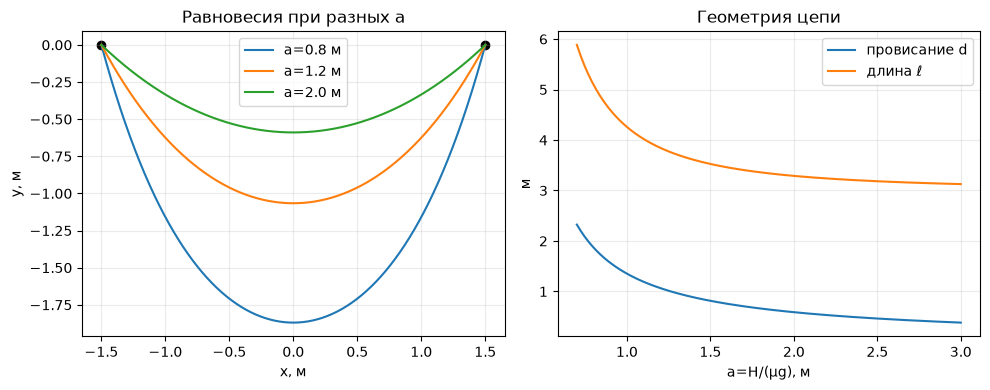

При пролёте 3 м и длине 4 м: a=1.110084 м.


In [6]:
z,A=sp.symbols('x a',real=True,positive=True)
shape=A*sp.cosh(z/A)
assert sp.simplify(sp.diff(shape,z,2)-sp.cosh(z/A)/A)==0
L=1.5; xx=np.linspace(-L,L,400)
fig,axes=plt.subplots(1,2,figsize=(10,4))
for tension_scale in [.8,1.2,2.]:
    yy=tension_scale*(np.cosh(xx/tension_scale)-np.cosh(L/tension_scale))
    axes[0].plot(xx,yy,label=f'a={tension_scale} м')
axes[0].scatter([-L,L],[0,0],c='black')
axes[0].set(xlabel='x, м',ylabel='y, м',title='Равновесия при разных a');axes[0].legend()
aa=np.linspace(.7,3,200)
axes[1].plot(aa,aa*(np.cosh(L/aa)-1),label='провисание d')
axes[1].plot(aa,2*aa*np.sinh(L/aa),label='длина ℓ')
axes[1].set(xlabel='a=H/(μg), м',ylabel='м',title='Геометрия цепи');axes[1].legend()
save_plot(fig,'3_3_catenary')
from scipy.optimize import brentq
length=4.
solved_a=brentq(lambda q:2*q*np.sinh(L/q)-length,.2,20.)
assert abs(2*solved_a*np.sinh(L/solved_a)-length)<1e-10
print(f'При пролёте 3 м и длине 4 м: a={solved_a:.6f} м.')

In [7]:
parameters=1.4+.6*np.cos(np.linspace(0,2*np.pi,80))
fig,ax=plt.subplots(figsize=(7,4),dpi=70)
ax.set(xlim=(-1.9,1.9),ylim=(-2.2,.7),xlabel='x, м',ylabel='y, м')
line,=ax.plot([],[],lw=2);ax.plot([-L,L],[0,0],'ks')
label=ax.text(.03,.9,'',transform=ax.transAxes)
arrows=[]
def update_chain(i):
    for art in arrows: art.remove()
    arrows.clear()
    av=parameters[i];yv=av*(np.cosh(xx/av)-np.cosh(L/av))
    line.set_data(xx,yv)
    # Силы для малого участка [-h,h], перенесённые в центр для сравнения.
    H=1.;w=H/av;h=.25;center=av*(1-np.cosh(L/av))
    span=2*av*np.sinh(h/av);weight=w*span;scale=.45
    for dx,dy,color in [(-H,H*np.sinh(h/av),'tab:blue'),
                        (H,H*np.sinh(h/av),'tab:blue'),(0,-weight,'tab:red')]:
        art=ax.annotate('',xy=(scale*dx,center+scale*dy),xytext=(0,center),
                        arrowprops=dict(arrowstyle='->',color=color,lw=2))
        arrows.append(art)
    assert np.isclose(2*H*np.sinh(h/av),weight)
    label.set_text(f'a={av:.2f} м; H=1 Н; μ={w/g:.3f} кг/м; d={-center:.2f} м')
    ax.set_title('3.3 Семейство равновесий; синие — натяжения, красная — вес')
anim33=show_animation(fig,update_chain,'3_3_catenary')

## 3.4 Таутохрона

Нижняя точка имеет высоту $y=0$. Точка стартует без скорости с высоты $h>0$.
Из сохранения энергии $v=\sqrt{2g(h-y)}$. Пусть $s(y)$ — длина дуги от
нижней точки по одной монотонной ветви, $s(0)=0$. Время спуска:
$$T(h)=\frac1{\sqrt{2g}}\int_0^h\frac{s'(y)}{\sqrt{h-y}}\,dy=T_0.$$
Это интегральное уравнение Абеля. Умножим его на $1/\sqrt{Y-h}$,
проинтегрируем по $h\in[0,Y]$ и поменяем порядок интегрирования:
$$\sqrt{2g}T_0\int_0^Y\frac{dh}{\sqrt{Y-h}}
=\int_0^Ys'(y)\left[\int_y^Y\frac{dh}{\sqrt{(h-y)(Y-h)}}\right]dy.$$
Внутренний интеграл равен $\pi$ (подстановка $h=y+(Y-y)\sin^2u$),
поэтому $2\sqrt{2g}T_0\sqrt Y=\pi s(Y)$.
Обозначим $a=gT_0^2/\pi^2$. Тогда
$$s=\sqrt{8ay},\qquad y=\frac{s^2}{8a}.$$
Из $dx^2+dy^2=ds^2$ и $s=4a\sin(\theta/2)$ получаем
$$\boxed{x=a(\theta+\sin\theta),\quad y=a(1-\cos\theta)},\quad -\pi<\theta<\pi.$$
Начало координат находится в нижней точке. Это перевёрнутая относительно
обычной арки циклоида; $a$ — радиус образующей окружности.

Касательное уравнение движения в ориентированной координате дуги:
$$\ddot s=-g\frac{dy}{ds}=-\frac{g}{4a}s.$$
При старте из покоя $s(t)=s_0\cos(\omega t)$, $\omega=\sqrt{g/(4a)}$.
Первое достижение низа происходит через четверть периода:
$$\boxed{T_0=\frac{\pi}{2\omega}=\pi\sqrt{a/g}}.$$
Время не зависит от ненулевого $s_0$ при $|s_0|<4a$.
Это скольжение материальной точки без трения, а не качение шарика с учётом его вращения.
Точка, изначально находящаяся внизу, никуда не спускается.

**Геометрия качения:** при $u\in[0,2\pi]$ центр окружности
$(a(u-\pi),a)$, точка обода
$(a(u-\sin u-\pi),a(1+\cos u))$. Окружность катится по прямой $y=2a$;
получается та же ветвь циклоида после сдвига и отражения обычной конструкции.

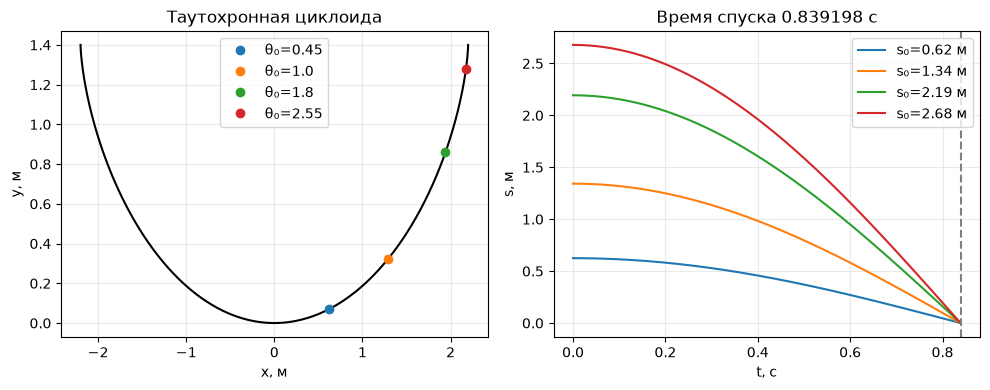

Все четыре точки приходят вниз через 0.839197901 с.


In [8]:
radius=.7;omega=np.sqrt(g/(4*radius));descent_time=np.pi*np.sqrt(radius/g)
theta=np.linspace(-np.pi,np.pi,700)
cx=radius*(theta+np.sin(theta));cy=radius*(1-np.cos(theta))
starts=np.array([.45,1.,1.8,2.55])
arc0=4*radius*np.sin(starts/2)
for h0 in radius*(1-np.cos(starts)):
    # y=h sin²u удаляет обе интегрируемые особенности уравнения Абеля.
    value=quad(lambda u:2*np.sqrt(2*radius),0,np.pi/2)[0]/np.sqrt(2*g)
    assert np.isclose(value,descent_time)
fig,axes=plt.subplots(1,2,figsize=(10,4))
axes[0].plot(cx,cy,color='black')
for angle in starts:
    axes[0].plot(radius*(angle+np.sin(angle)),radius*(1-np.cos(angle)),'o',label=f'θ₀={angle}')
axes[0].set(xlabel='x, м',ylabel='y, м',title='Таутохронная циклоида');axes[0].legend()
tt=np.linspace(0,descent_time,200)
for s0 in arc0:axes[1].plot(tt,s0*np.cos(omega*tt),label=f's₀={s0:.2f} м')
axes[1].axvline(descent_time,ls='--',color='.5')
axes[1].set(xlabel='t, с',ylabel='s, м',title=f'Время спуска {descent_time:.6f} с');axes[1].legend()
save_plot(fig,'3_4_tautochrone')
assert np.allclose(arc0*np.cos(omega*descent_time),0,atol=1e-12)
print(f'Все четыре точки приходят вниз через {descent_time:.9f} с.')

In [9]:
fig,axes=plt.subplots(1,2,figsize=(10,4),dpi=65)
for ax in axes:
    ax.plot(cx,cy,color='.55');ax.set(xlim=(-2.5,2.5),ylim=(-.2,2),xlabel='x, м',ylabel='y, м')
axes[0].set_title('Одновременный спуск из покоя')
balls=[axes[0].plot([],[],'o',ms=7)[0] for _ in arc0]
stamp=axes[0].text(.03,.94,'',transform=axes[0].transAxes)
axes[1].axhline(2*radius,color='.5',ls='--');axes[1].set_title('Качение образующей окружности')
axes[1].set_xlim(-np.pi*radius-radius-.2,np.pi*radius+radius+.2)
for ax in axes: ax.set_aspect('equal',adjustable='box')
circle,=axes[1].plot([],[],color='tab:blue');spoke,=axes[1].plot([],[],color='tab:blue')
trace,=axes[1].plot([],[],color='tab:red');marker,=axes[1].plot([],[],'ro')
def update_tautochrone(i):
    fraction=i/79;t=fraction*descent_time
    s=arc0*np.cos(omega*t);angles=2*np.arcsin(np.clip(s/(4*radius),-1,1))
    for dot,q in zip(balls,angles):dot.set_data([radius*(q+np.sin(q))],[radius*(1-np.cos(q))])
    stamp.set_text(f't={t:.3f} с; T={descent_time:.3f} с')
    u=2*np.pi*fraction;center=np.array([radius*(u-np.pi),radius])
    ph=np.linspace(0,2*np.pi,100)
    circle.set_data(center[0]+radius*np.cos(ph),center[1]+radius*np.sin(ph))
    p=np.array([radius*(u-np.sin(u)-np.pi),radius*(1+np.cos(u))])
    spoke.set_data([center[0],p[0]],[center[1],p[1]]);marker.set_data([p[0]],[p[1]])
    uu=np.linspace(0,u,200);trace.set_data(radius*(uu-np.sin(uu)-np.pi),radius*(1+np.cos(uu)))
fig.tight_layout();anim34=show_animation(fig,update_tautochrone,'3_4_tautochrone')

## 3.5 Математический маятник

Масса $m$ закреплена на невесомом нерастяжимом стержне длины $l$.
Угол $\theta$ отсчитывается от вертикали вниз; сопротивления нет.
Момент силы тяжести $-mgl\sin\theta$ даёт
$$ml^2\ddot\theta=-mgl\sin\theta,\quad
\boxed{\ddot\theta+\frac gl\sin\theta=0}.$$
При $|\theta|\ll1$ заменяем $\sin\theta\approx\theta$:
$$\theta(t)=\theta_0\cos(\omega_0t)+\frac{\dot\theta_0}{\omega_0}\sin(\omega_0t),
\quad \omega_0=\sqrt{g/l},\quad T_{\rm lin}=2\pi\sqrt{l/g}.$$

**Энергия и фазовая плоскость.** Умножение ДУ на $\dot\theta$ даёт первый интеграл
$$e=\tfrac12\dot\theta^2+\frac gl(1-\cos\theta)=\mathrm{const}.$$
Физическая энергия равна $ml^2e$. Устойчивые равновесия
$(2k\pi,0)$ — центры, неустойчивые $((2k+1)\pi,0)$ — седла.
При $0<e<2g/l$ идут колебания; при $e>2g/l$ — вращения;
$e=2g/l$ — сепаратриса
$$\dot\theta=\pm2\sqrt{g/l}\,|\cos(\theta/2)|,\quad -\pi\le\theta\le\pi.$$

**Точное решение для старта из покоя** $0<\theta_0<\pi$.
Положим $k=\sin(\theta_0/2)$, $m_e=k^2$ (это параметр эллиптических функций,
не масса). Из энергии
$$\dot\theta^2=4\omega_0^2[k^2-\sin^2(\theta/2)].$$
Подстановка $\sin(\theta/2)=k\sin\phi$ приводит к
$$T=\frac4{\omega_0}\int_0^{\pi/2}\frac{d\phi}{\sqrt{1-k^2\sin^2\phi}}
=4\sqrt{l/g}\,K(m_e).$$
В принятом здесь параметрическом обозначении
$K(m_e)=\int_0^{\pi/2}(1-m_e\sin^2\phi)^{-1/2}d\phi$.
С помощью функции Якоби:
$$\boxed{\theta(t)=2\arcsin[k\,\operatorname{sn}(K(m_e)-\omega_0t\mid m_e)]}.$$
При $k\to0$ получаем гармоническое решение; при $\theta_0\to\pi$ период
неограниченно растёт. Начало из точно верхней точки с нулевой скоростью
даёт неустойчивое неподвижное равновесие, а не колебание бесконечной амплитуды.
Ряды: $T/T_{\rm lin}=1+\theta_0^2/16+11\theta_0^4/3072+\cdots$.

В SciPy `ellipk` и `ellipj` принимают **параметр $m_e=k^2$**, а не модуль $k$.
В справочнике NIST формулы могут использовать модуль: обозначения надо сверять.
Для произвольных начальных условий и вращения ниже применяется `solve_ivp`.

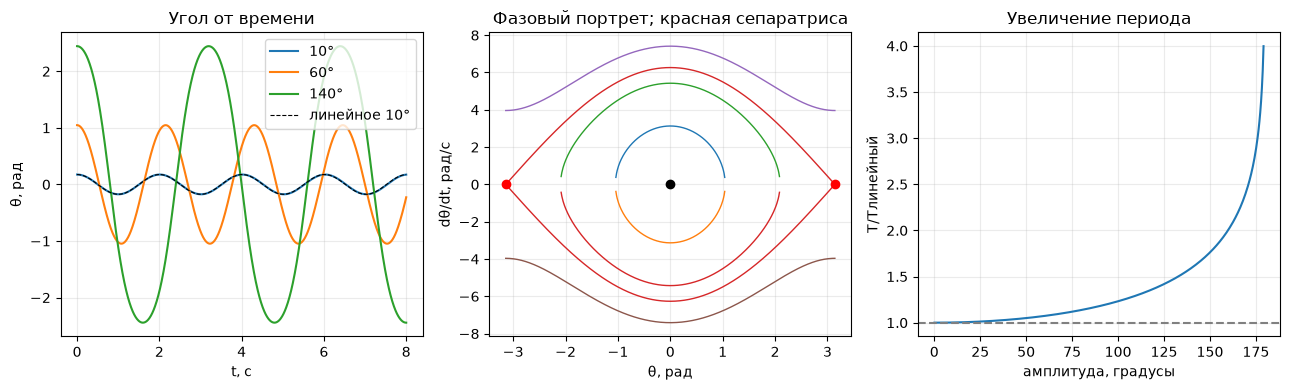

Амплитуда 10°: T=2.00989263 с
Амплитуда 60°: T=2.15287467 с
Амплитуда 140°: T=3.19856520 с
Сопоставлены точное и численное решения; проверено сохранение энергии.


In [10]:
length=1.;w0=np.sqrt(g/length);Tlinear=2*np.pi/w0
def pendulum_exact(time,amplitude):
    k=np.sin(amplitude/2);parameter=k*k;K=ellipk(parameter)
    sn,cn,dn,_=ellipj(K-w0*np.asarray(time),parameter)
    angle=2*np.arcsin(np.clip(k*sn,-1,1))
    angular=-2*k*w0*cn*dn/np.sqrt(1-(k*sn)**2)
    return angle,angular
def pendulum_rhs(time,state): return [state[1],-w0*w0*np.sin(state[0])]
sample=np.linspace(0,8,1200)
fig,axes=plt.subplots(1,3,figsize=(13,4))
for deg in [10,60,140]:
    amplitude=np.deg2rad(deg);angle,angular=pendulum_exact(sample,amplitude)
    numerical=solve_ivp(pendulum_rhs,[0,8],[amplitude,0],t_eval=sample,rtol=1e-10,atol=1e-12)
    assert np.max(np.abs(angle-numerical.y[0]))<2e-8
    axes[0].plot(sample,angle,label=f'{deg}°')
    energy=.5*angular**2+w0*w0*(1-np.cos(angle))
    assert np.ptp(energy)<1e-10
axes[0].plot(sample,np.deg2rad(10)*np.cos(w0*sample),'k--',lw=.8,label='линейное 10°')
axes[0].set(title='Угол от времени',xlabel='t, с',ylabel='θ, рад');axes[0].legend()
th=np.linspace(-np.pi,np.pi,500)
for E in [.5*w0*w0,1.5*w0*w0,2*w0*w0,2.8*w0*w0]:
    v2=2*(E-w0*w0*(1-np.cos(th)));vv=np.sqrt(np.maximum(v2,0));vv[v2<0]=np.nan
    for sign in [1,-1]:axes[1].plot(th,sign*vv,color='tab:red' if E==2*w0*w0 else None,lw=1)
axes[1].plot([0],[0],'ko');axes[1].plot([-np.pi,np.pi],[0,0],'ro')
axes[1].set(title='Фазовый портрет; красная сепаратриса',xlabel='θ, рад',ylabel='dθ/dt, рад/с')
amp=np.linspace(.001,np.pi-.015,400);period=4/w0*ellipk(np.sin(amp/2)**2)
axes[2].plot(np.rad2deg(amp),period/Tlinear);axes[2].axhline(1,color='.5',ls='--')
axes[2].set(title='Увеличение периода',xlabel='амплитуда, градусы',ylabel='T/Tлинейный')
save_plot(fig,'3_5_pendulum')
for deg in [10,60,140]:
    print(f'Амплитуда {deg}°: T={4/w0*ellipk(np.sin(np.deg2rad(deg)/2)**2):.8f} с')
print('Сопоставлены точное и численное решения; проверено сохранение энергии.')

In [11]:
times=np.linspace(0,6,80)
states=[pendulum_exact(times,np.deg2rad(v)) for v in [10,140]]
rotation=solve_ivp(pendulum_rhs,[0,6],[0,2.4*w0],t_eval=times,rtol=1e-10,atol=1e-12)
states.append(tuple(rotation.y))
fig,axes=plt.subplots(1,2,figsize=(9,4.5),dpi=65)
axes[0].set(xlim=(-1.2,1.2),ylim=(-1.2,1.2),aspect='equal',xlabel='x, м',ylabel='y, м',title='Маятники')
rods=[];points=[];phase_lines=[];phase_dots=[]
for name,(angles,vels),color in zip(['10°','140°','вращение'],states,['tab:blue','tab:orange','tab:green']):
    rods.append(axes[0].plot([],[],color=color,label=name)[0]);points.append(axes[0].plot([],[],'o',color=color)[0])
    phase_lines.append(axes[1].plot([],[],color=color)[0]);phase_dots.append(axes[1].plot([],[],'o',color=color)[0])
axes[0].legend(loc='upper right');axes[0].plot(0,0,'k.')
axes[1].set(xlim=(-np.pi,np.pi),ylim=(-8,8),xlabel='θ mod 2π',ylabel='dθ/dt',title='Фаза и сепаратриса')
axes[1].plot(th,2*w0*np.abs(np.cos(th/2)),'r--',lw=.7)
axes[1].plot(th,-2*w0*np.abs(np.cos(th/2)),'r--',lw=.7)
stamp=fig.suptitle('')
def update_pendulum(i):
    for (angles,vels),rod,dot,line,phase in zip(states,rods,points,phase_lines,phase_dots):
        x=length*np.sin(angles[i]);y=-length*np.cos(angles[i])
        rod.set_data([0,x],[0,y]);dot.set_data([x],[y])
        wrapped=(angles[:i+1]+np.pi)%(2*np.pi)-np.pi
        broken=wrapped.copy()
        if len(broken)>1:broken[1:][np.abs(np.diff(wrapped))>np.pi]=np.nan
        line.set_data(broken,vels[:i+1]);phase.set_data([wrapped[-1]],[vels[i]])
    stamp.set_text(f'3.5 Линейный предел, нелинейные колебания, вращение; t={times[i]:.2f} с')
fig.tight_layout();anim35=show_animation(fig,update_pendulum,'3_5_pendulum')

## Проверки и источники

Во всех задачах получены аналитические формулы, построены и сохранены PNG,
созданы управляемые анимации `FuncAnimation`. Проверки в коде охватывают
уравнение траектории, период бильярда, длину цепи и равновесие сил,
время таутохронного спуска, точность численного решения маятника и его энергию.

1. П. Е. Рябов. «Практические занятия Листок 3». Условия 3.1–3.5 из предоставленного PDF.
2. [NIST DLMF 22.19 — маятник и функции Якоби](https://dlmf.nist.gov/22.19).
3. [SciPy ellipj](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.ellipj.html),
   [ellipk](https://docs.scipy.org/doc/scipy/reference/generated/scipy.special.ellipk.html).
4. [Matplotlib FuncAnimation](https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.FuncAnimation.html).

Анимация семейства цепных линий не описывает переходный процесс одной цепи.
В бильярде термин «эргодичность» относится к потоку с фиксированным иррациональным направлением на торе.